# Bounce paired Δ: how one value and its error are derived (v3)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-10-28  
**Last Modified:** 2026-10-29  
**Status:** In Progress  
**Keywords:** bounce, paired difference, DZ, temporal trend, BLOCK-T720  

## Description

For one double-Zernike term DZ_kj and a list of nights, this notebook shows every
step from the per-visit values to the single paired Δ and error the bounce
analysis reports, using the same library functions (`rubinwork.bounce.legs`).

1. Per-visit DZ_kj for every A (reference) and B (comparison) visit, in time order.
2. The (A, B) pairs `form_pairs` makes, the per-pair differences B − A, their
   median (Δ) and the error `1.2533 × 1.4826 × MAD / √n`.
3. Two drift-resistant alternatives: A–B–A (each B minus the A interpolated
   to its time from its neighbours), and a per-night Huber fit of `DZ = a + s·t + Δ·[B]`, which
   removes a linear drift, against the paired Δ; and the bias a drift `s` gives
   the paired Δ through the mean B − A time lag of the pairs.

**Output:** per-(night, leg) figures and a summary CSV in the study run directory.

**Based on:** `aos/bounce/study.md`, Log 2026-10-28 (the 40 deg nights disagree
beyond their errors, worst in DZ(1,4)).

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-10-28 | Aaron Roodman | Initial version |
| 2026-10-29 | Aaron Roodman | v2: per-visit error model (fit error plus coherent turbulence), propagated through the four estimators |
| 2026-10-29 | Aaron Roodman | v3: red-noise (time-correlated) error model fit to the variogram; significance of the 40 deg points |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Per-visit values and pairs](#visits)
6. [Paired Δ derivation, per night and leg](#derivation)
7. [Temporal trend](#trend)
8. [Error model](#errmodel)
9. [The white floor](#floor)
10. [Variogram and red-noise model](#variogram)
11. [Estimator errors under the red-noise model](#esterr)
12. [Summary](#summary)
13. [How far are the 40 deg points from the rest?](#signif)

<a id='params'></a>
## Parameters

In [1]:
# DZ term: focal-plane Zernike k, pupil Zernike j (Noll)
K, J = 1, 4
# Nights to study (day_obs)
DAY_OBS = [20260418, 20260419, 20260513, 20260709, 20260711, 20260713]
BOUNCE = 'T720_elevation'          # bounce name from analysis_config.yaml

# Fit table: the measured-intrinsic refit, as the bounce run reads it
PARAM_SET = 'danish_1_3'
MI_NAME = 'pathA_50_50_i_rbr_5rot'
MIW_VARIANT = 'd13-A_50_50_i_rbr_5rot'
MIW_BUILD = '20261028b'
MIN_DETECTORS = 160                # the bounce run's --min-detectors

HUBER_T = 1.345                    # Huber threshold, in robust sigma (dimensionless)
# v2 white-noise turbulence error per visit, um of wavefront (0.04 um: the Z4
# value of an old simulation).  v3 fits the white floor and red noise to the data
# instead; this value is kept for the comparison column only.
SIGMA_TURB_UM = 0.04
SAVE = True                        # write figures and the summary CSV to the run dir

from rubinwork.common import study_run
run = study_run('aos/bounce', f'delta_derivation_v3_dz{K}_{J}')

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import statsmodels.api as sm
from scipy import stats

from rubinwork.bounce import legs as bl
from rubinwork.bounce import analysis as ba
from rubinwork.common.utils import alt_to_deg, nmad, repo_root
from rubinwork.products import catalog

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

<a id='functions'></a>
## Helper Functions

In [3]:
def paired_reduction(diffs):
    """The bounce reduction of per-pair differences, step by step.

    Parameters
    ----------
    diffs : `numpy.ndarray`
        Per-pair B − A differences, um of wavefront.

    Returns
    -------
    r : `dict`
        ``delta`` (median, um), ``mad`` (median absolute deviation about the
        median, um), ``sigma`` (1.4826 MAD, um), ``err`` (1.2533 sigma / sqrt n,
        um), ``n``, and for comparison ``mean``, ``std`` and ``err_mean``
        (std / sqrt n), all um.
    """
    d = np.asarray(diffs, float)
    d = d[np.isfinite(d)]
    n = d.size
    delta = float(np.median(d))
    mad = float(np.median(np.abs(d - delta)))
    sigma = 1.4826 * mad
    return {'n': n, 'delta': delta, 'mad': mad, 'sigma': sigma,
            'err': 1.2533 * sigma / np.sqrt(n),
            'mean': float(np.mean(d)),
            'std': float(np.std(d, ddof=1)) if n > 1 else np.nan,
            'err_mean': float(np.std(d, ddof=1) / np.sqrt(n)) if n > 1 else np.nan}


def aba_diffs(v):
    """Each B minus the A interpolated linearly to its time, from the A visits
    just before and just after it (a B with no A on both sides is skipped).

    Parameters
    ----------
    v : `pandas.DataFrame`
        One (night, leg)'s visits with ``setting``, ``seq_num``, ``t_min`` and
        ``dz_um``.

    Returns
    -------
    diffs : `numpy.ndarray`
        B − A_interp, um of wavefront.
    """
    A = v[v.setting == 'A'].sort_values('seq_num')
    out = []
    for _, bb in v[v.setting == 'B'].iterrows():
        a0 = A[A.seq_num < bb.seq_num]; a1 = A[A.seq_num > bb.seq_num]
        if len(a0) and len(a1):
            a0, a1 = a0.iloc[-1], a1.iloc[0]
            f = (bb.t_min - a0.t_min) / (a1.t_min - a0.t_min)
            out.append(bb.dz_um - (a0.dz_um + f * (a1.dz_um - a0.dz_um)))
    return np.array(out, float)


def huber_step_trend(t, y, is_b):
    """Huber fit of ``y = a + s t + delta [B]`` for one night.

    Parameters
    ----------
    t : `numpy.ndarray`
        Time since the night's first A/B visit, min.
    y : `numpy.ndarray`
        DZ_kj, um of wavefront.
    is_b : `numpy.ndarray` [`bool`]
        True for a B (comparison) visit.

    Returns
    -------
    fit : `dict`
        ``a`` (um), ``s`` (um/min), ``delta`` (um) with errors ``*_err``, and the
        robust ``scale`` (um).  The no-trend fit ``y = a + delta [B]`` is in
        ``delta0``, ``delta0_err``.
    """
    X = np.column_stack([np.ones_like(t), t, is_b.astype(float)])
    r = sm.RLM(y, X, M=sm.robust.norms.HuberT(t=HUBER_T)).fit()
    X0 = np.column_stack([np.ones_like(t), is_b.astype(float)])
    r0 = sm.RLM(y, X0, M=sm.robust.norms.HuberT(t=HUBER_T)).fit()
    return {'a': r.params[0], 's': r.params[1], 'delta': r.params[2],
            'a_err': r.bse[0], 's_err': r.bse[1], 'delta_err': r.bse[2],
            'scale': r.scale, 'delta0': r0.params[1], 'delta0_err': r0.bse[1]}

<a id='data'></a>
## Data Access

The fit table goes through the same bad-fit drop and quality cut as the bounce run.

In [4]:
cfg = bl.resolve_config(PARAM_SET, MI_NAME,
                        analysis_config=repo_root() / 'aos' / 'analysis_config.yaml')
prefix = cfg['fit_prefix']
b = next(x for x in cfg['bounces'] if x['name'] == BOUNCE)
fits_path = catalog.path('miw', MIW_VARIANT, build=MIW_BUILD) / 'fits.parquet'
ft = ba.load_fit_table(fits_path, cfg, min_detectors=MIN_DETECTORS)
col = f'{prefix}_z{J}_c{K}'
print(f'{len(ft)} visits; column {col}; bounce {BOUNCE}: '
      f'ref {b["reference"]}, legs {[c["label"] for c in b["comparisons"]]}')

  dropping 11 bad-flagged visits (z1toz6_bad_fit)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


INFO:lsst.ts.utils.tai:Update leap second table


INFO:lsst.ts.utils.tai:current_tai uses the system TAI clock


  quality cut (min_detectors=160): 1575/2012 visits kept
1575 visits; column z1toz6_z4_c1; bounce T720_elevation: ref {'label': 'Elev=70', 'alt_range': [67.0, 73.0], 'rotator_range': [-3.0, 3.0]}, legs ['Elev=40', 'Elev=60', 'Elev=50', 'Elev=30', 'Elev=75']


<a id='visits'></a>
## Per-visit values and pairs

For each night, `run_bounce(..., day_obs=night)` gives the A mask, each B leg's
mask and the pairs, exactly as the bounce run's per-night results. `form_pairs`
walks the A and B visits in seq_num order and pairs each visit with the next one
of the other setting; a run of same-setting visits keeps only the latest.

In [5]:
dobs = np.asarray(ft['day_obs']).astype(int)
seq = np.asarray(ft['seq_num']).astype(int)
mjd = np.asarray(ft['mjd'], float)
alt = np.asarray(alt_to_deg(ft['alt']), float)
rot = np.asarray(ft['rotator_angle'], float)
y_all = np.asarray(ft[col], float)
yerr_all = np.asarray(ft[col + '_err'], float) if col + '_err' in ft.colnames else None
prog = bl.bounce_program_mask(ft, b)

visits, pairs_rows, legs = [], [], []
for d in DAY_OBS:
    rb = bl.run_bounce(ft, b, prefix, [K], [J], day_obs=d)
    night = (dobs == d) & prog
    if not night.any():
        print(f'{d}: no {b["program"]} visits'); continue
    t0 = mjd[night].min()
    for lab, cb in rb['comparisons'].items():
        if not cb['pairs']:
            continue
        legs.append({'night': d, 'leg': lab, 'ref_mask': rb['ref_mask'],
                     'comp_mask': cb['comp_mask'], 'pairs': cb['pairs'],
                     'pipeline': cb['deltas'][(K, J)], 't0': t0})
        paired = {i for p in cb['pairs'] for i in p}
        for i in np.nonzero(night)[0]:
            setting = ('A' if rb['ref_mask'][i] else
                       'B' if cb['comp_mask'][i] else 'other')
            visits.append({'night': d, 'leg': lab, 'row': i, 'seq_num': seq[i],
                           't_min': (mjd[i] - t0) * 1440.0, 'alt_deg': alt[i],
                           'rot_deg': rot[i], 'setting': setting,
                           'paired': i in paired, 'dz_um': y_all[i],
                           'dz_err_um': np.nan if yerr_all is None else yerr_all[i]})
        for pi, (r, c) in enumerate(cb['pairs']):
            pairs_rows.append({'night': d, 'leg': lab, 'pair': pi,
                               'seq_A': seq[r], 'seq_B': seq[c],
                               't_A_min': (mjd[r] - t0) * 1440.0,
                               't_B_min': (mjd[c] - t0) * 1440.0,
                               'dz_A_um': y_all[r], 'dz_B_um': y_all[c],
                               'diff_um': y_all[c] - y_all[r]})
vdf = pd.DataFrame(visits)
pdf_pairs = pd.DataFrame(pairs_rows)
pdf_pairs['lag_min'] = pdf_pairs['t_B_min'] - pdf_pairs['t_A_min']
print(f'{len(legs)} (night, leg) samples, {len(pdf_pairs)} pairs')
pdf_pairs

7 (night, leg) samples, 45 pairs


,night,leg,pair,seq_A,seq_B,t_A_min,t_B_min,dz_A_um,dz_B_um,diff_um,lag_min
0,20260418,Elev=40,0,356,359,0.000000,2.837384,0.213305,0.126196,-0.087109,2.837384
1,20260418,Elev=40,1,362,365,5.612348,8.414376,0.239269,0.087498,-0.151771,2.802027
2,20260418,Elev=40,2,368,371,11.179521,13.942709,0.208748,0.084371,-0.124377,2.763189
3,20260418,Elev=40,3,374,377,16.689010,19.443963,0.096674,0.015667,-0.081008,2.754953
4,20260418,Elev=40,4,380,383,22.230853,25.007335,0.004314,-0.085684,-0.089998,2.776482
5,20260418,Elev=40,5,386,389,27.791504,30.584653,-0.144663,-0.338235,-0.193573,2.793149
6,20260419,Elev=40,0,279,282,5.575834,8.355072,0.048994,-0.100443,-0.149438,2.779238
7,20260419,Elev=40,1,285,288,11.148081,13.935926,0.077609,-0.149458,-0.227066,2.787845
8,20260419,Elev=40,2,297,300,22.303337,25.102648,0.081732,-0.053468,-0.135199,2.799312
9,20260419,Elev=40,3,303,306,27.882338,30.664405,0.146444,-0.054673,-0.201117,2.782067


<a id='derivation'></a>
## Paired Δ derivation, per night and leg

One figure per (night, leg):

- **left**: DZ_kj per visit vs time; A filled circles, B filled squares, visits of
  the program not in this leg gray; a line joins each pair; unpaired A/B visits
  are open markers. Per-visit fit errors are drawn but are much smaller than the
  scatter.
- **middle**: the per-pair differences B − A in pair order, the median Δ, the
  error band ±err and the robust-scatter band ±1.4826 MAD.
- **right**: the same differences against the pair's B − A time lag. A drift
  shows here as a slope; a constant lag sign means the drift biases Δ.

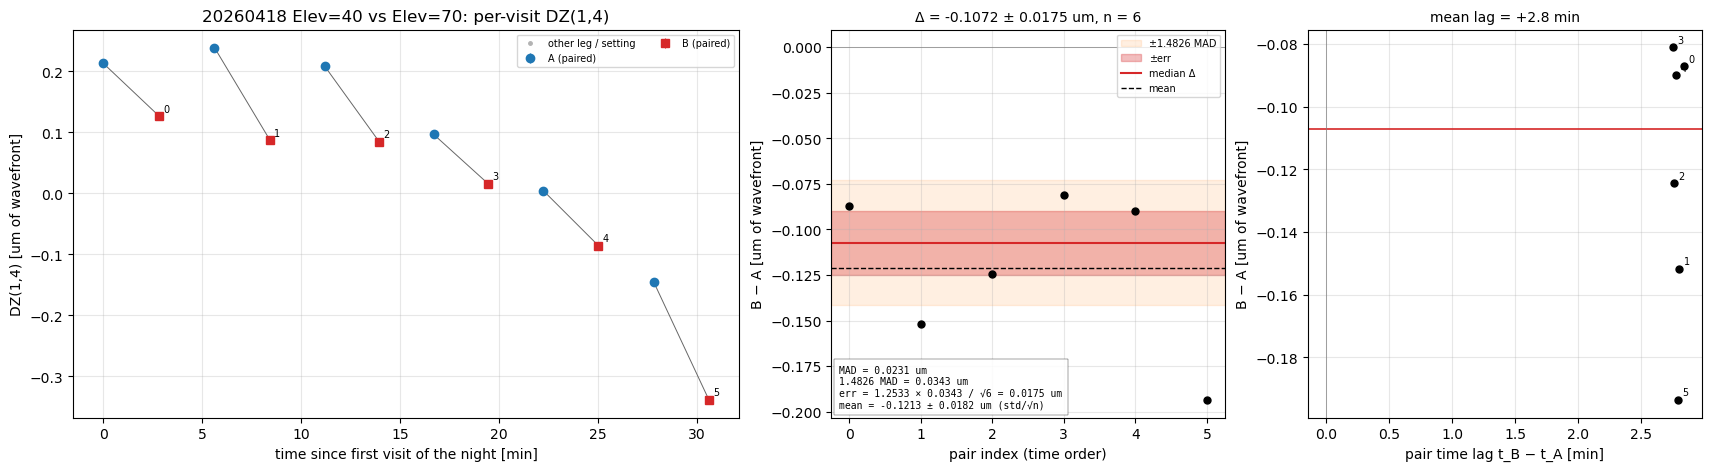

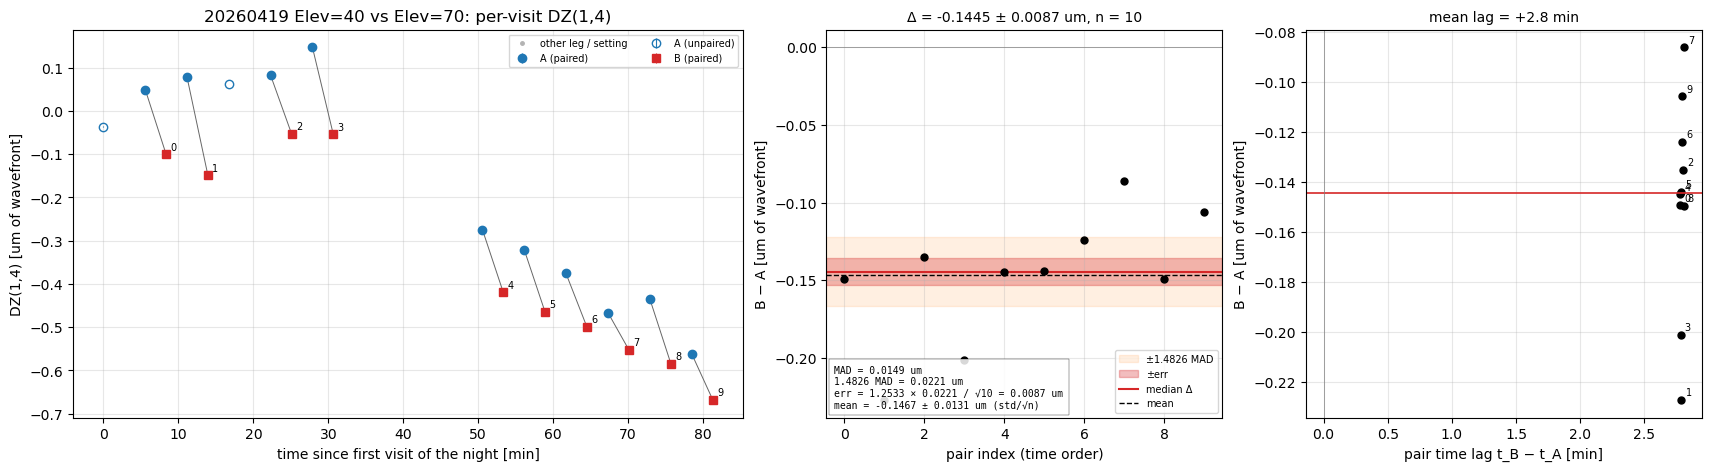

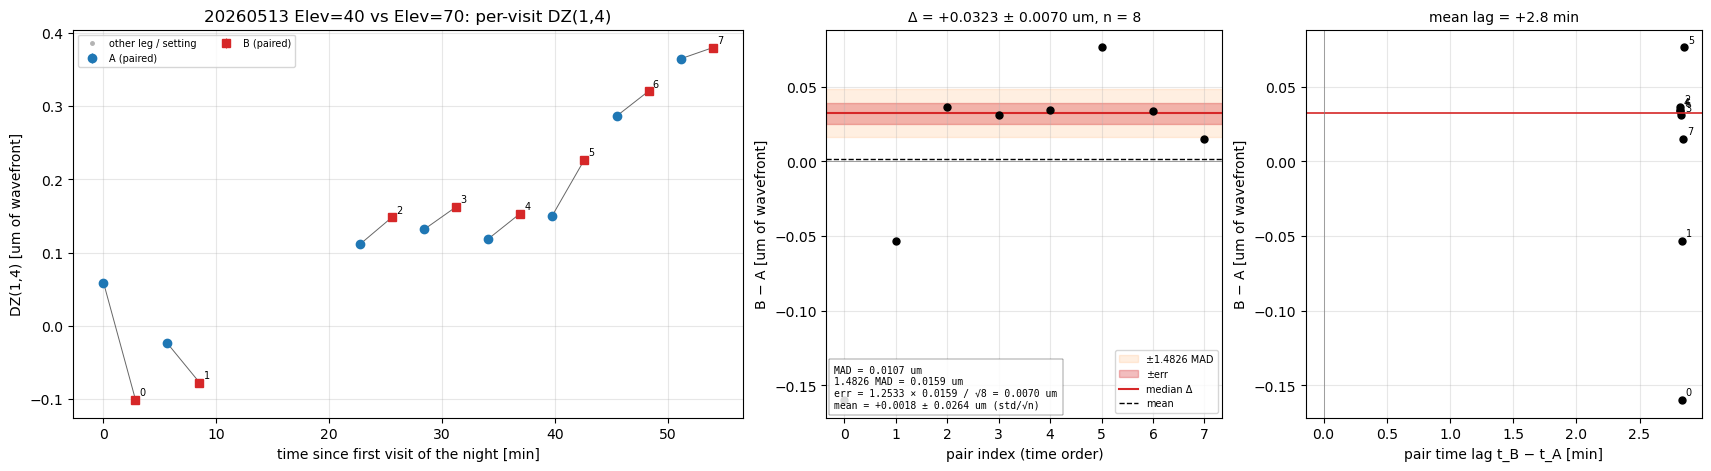

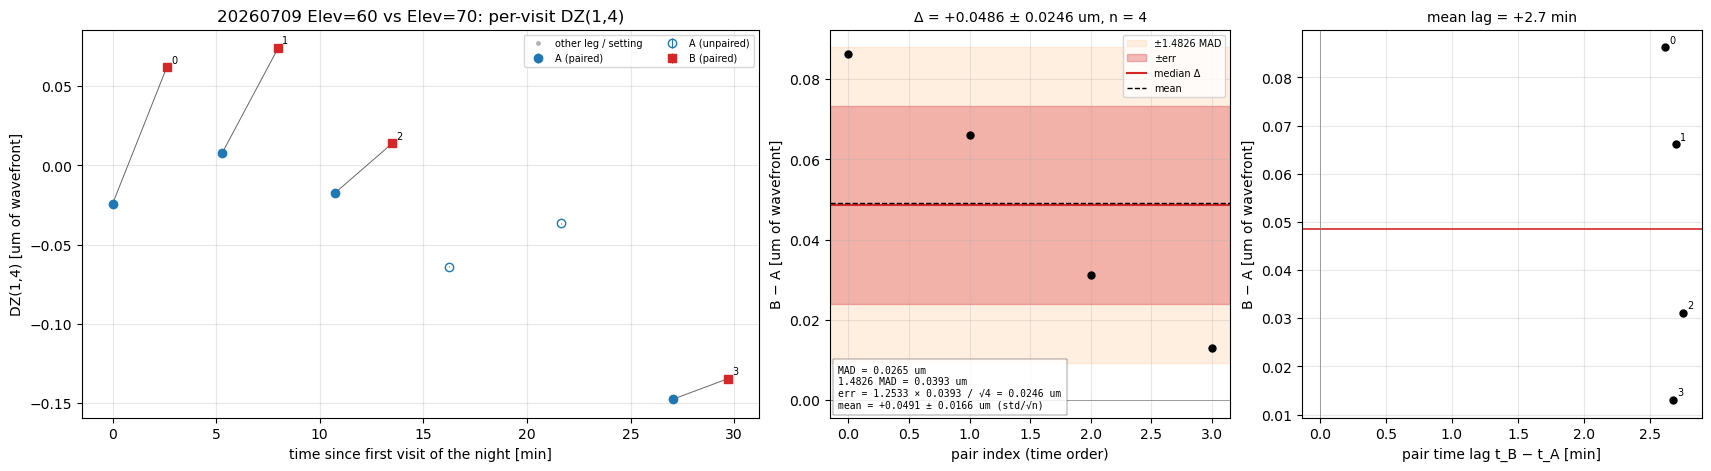

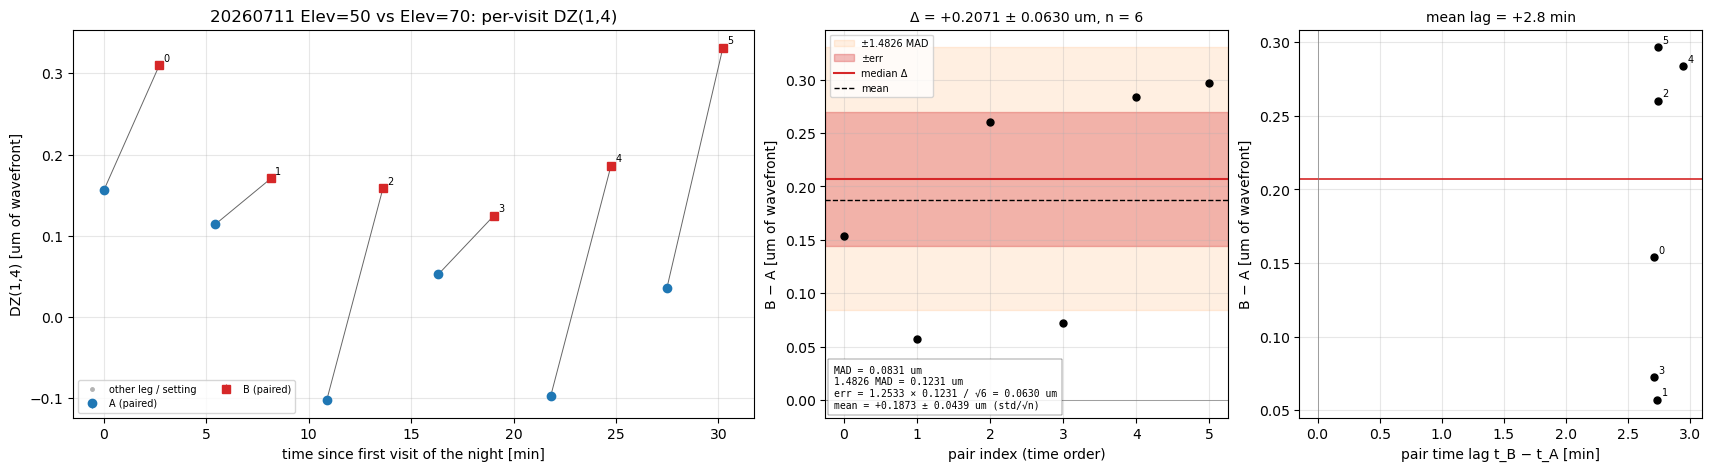

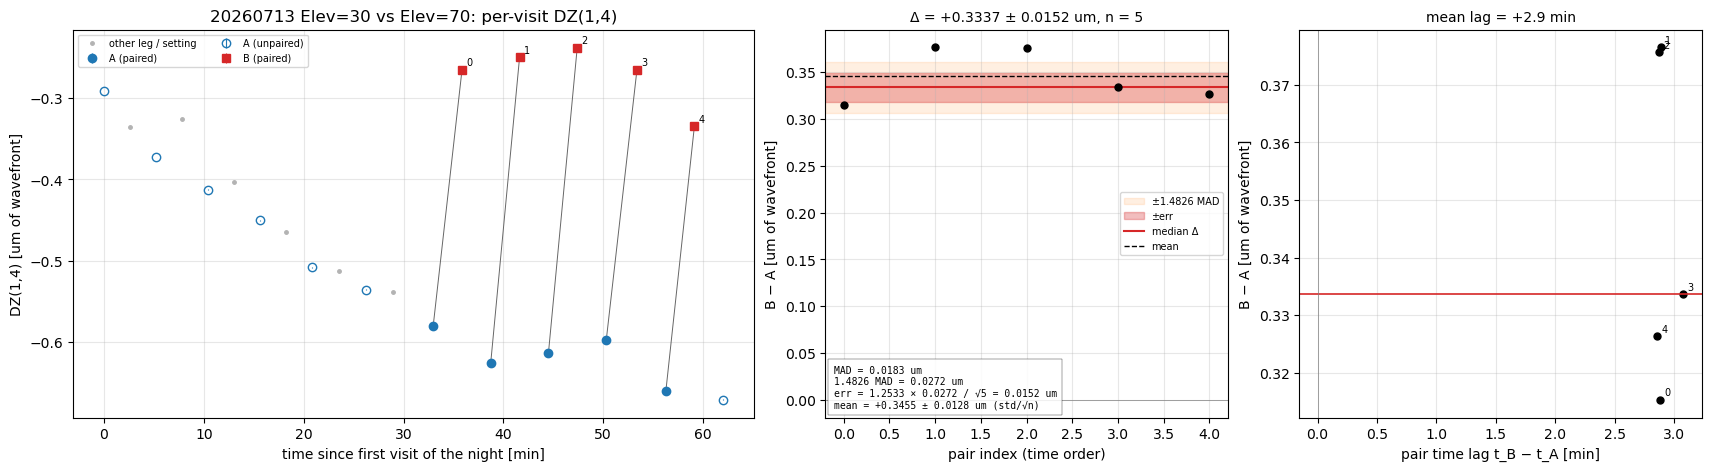

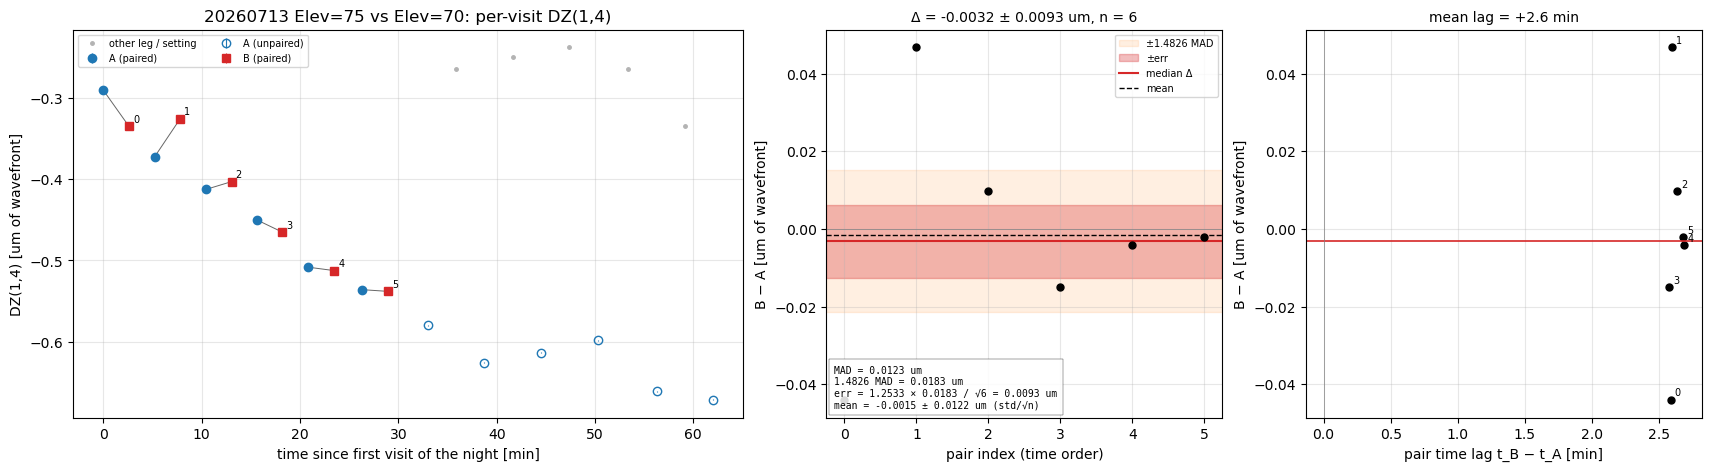

,night,leg,b_value_deg,n_A,n_B,n_pairs,delta_um,err_um,sigma_um,mean_um,err_mean_um,mean_lag_min
0,20260418,Elev=40,40.0,6,6,6,-0.107188,0.017545,0.034291,-0.121306,0.018197,2.787864
1,20260419,Elev=40,40.0,12,10,10,-0.144455,0.008749,0.022076,-0.146721,0.013089,2.791333
2,20260513,Elev=40,40.0,8,8,8,0.032330,0.007045,0.015900,0.001807,0.026404,2.830981
3,20260709,Elev=60,60.0,6,4,4,0.048639,0.024631,0.039306,0.049146,0.016553,2.684768
4,20260711,Elev=50,50.0,6,6,6,0.207116,0.063007,0.123143,0.187281,0.043948,2.763077
5,20260713,Elev=30,30.0,12,5,5,0.333656,0.015238,0.027187,0.345494,0.012821,2.917070
6,20260713,Elev=75,75.0,12,6,6,-0.003203,0.009342,0.018259,-0.001491,0.012187,2.624163


In [6]:
rows = []
figs = []
for L in legs:
    d, lab = L['night'], L['leg']
    v = vdf[(vdf.night == d) & (vdf.leg == lab)]
    pp = pdf_pairs[(pdf_pairs.night == d) & (pdf_pairs.leg == lab)]
    red = paired_reduction(pp['diff_um'].to_numpy())
    pipe = L['pipeline']
    assert np.isclose(red['delta'], pipe['delta']) and np.isclose(red['err'], pipe['err'])
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout='constrained',
                           gridspec_kw={'width_ratios': [2.2, 1.3, 1.3]})
    o = v[v.setting == 'other']
    ax[0].plot(o.t_min, o.dz_um, '.', color='0.7', ms=5, label='other leg / setting')
    for s, mk, cl in (('A', 'o', '#1f77b4'), ('B', 's', '#d62728')):
        w = v[v.setting == s]
        for pd_, fc in ((True, cl), (False, 'none')):
            ww = w[w.paired == pd_]
            if len(ww):
                ax[0].errorbar(ww.t_min, ww.dz_um, yerr=ww.dz_err_um, fmt=mk, ms=6,
                               mfc=fc, mec=cl, color=cl, elinewidth=0.8,
                               label=f'{s} ({"paired" if pd_ else "unpaired"})')
    for _, p in pp.iterrows():
        ax[0].plot([p.t_A_min, p.t_B_min], [p.dz_A_um, p.dz_B_um], '-', color='0.4', lw=0.7)
        ax[0].annotate(str(int(p.pair)), (p.t_B_min, p.dz_B_um), fontsize=7,
                       xytext=(3, 3), textcoords='offset points')
    ax[0].set_xlabel('time since first visit of the night [min]')
    ax[0].set_ylabel(f'DZ({K},{J}) [um of wavefront]')
    ax[0].set_title(f'{d} {lab} vs {b["reference"]["label"]}: per-visit DZ({K},{J})')
    ax[0].legend(fontsize=7, ncols=2); ax[0].grid(alpha=0.3)

    x = pp['pair'].to_numpy()
    ax[1].axhspan(red['delta'] - red['sigma'], red['delta'] + red['sigma'],
                  color='#ff7f0e', alpha=0.12, label='±1.4826 MAD')
    ax[1].axhspan(red['delta'] - red['err'], red['delta'] + red['err'],
                  color='#d62728', alpha=0.3, label='±err')
    ax[1].axhline(red['delta'], color='#d62728', lw=1.5, label='median Δ')
    ax[1].axhline(red['mean'], color='k', lw=1, ls='--', label='mean')
    ax[1].plot(x, pp['diff_um'], 'ko', ms=5)
    ax[1].axhline(0, color='gray', lw=0.5)
    ax[1].set_xlabel('pair index (time order)')
    ax[1].set_ylabel('B − A [um of wavefront]')
    ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
    ax[1].set_title(f"Δ = {red['delta']:+.4f} ± {red['err']:.4f} um, n = {red['n']}", fontsize=10)
    txt = (f"MAD = {red['mad']:.4f} um\n1.4826 MAD = {red['sigma']:.4f} um\n"
           f"err = 1.2533 × {red['sigma']:.4f} / √{red['n']} = {red['err']:.4f} um\n"
           f"mean = {red['mean']:+.4f} ± {red['err_mean']:.4f} um (std/√n)")
    ax[1].text(0.02, 0.02, txt, transform=ax[1].transAxes, fontsize=7, va='bottom',
               family='monospace', bbox=dict(fc='white', alpha=0.85, lw=0.3))

    ax[2].plot(pp['lag_min'], pp['diff_um'], 'ko', ms=5)
    for _, p in pp.iterrows():
        ax[2].annotate(str(int(p.pair)), (p.lag_min, p.diff_um), fontsize=7,
                       xytext=(3, 3), textcoords='offset points')
    ax[2].axhline(red['delta'], color='#d62728', lw=1.2)
    ax[2].axvline(0, color='gray', lw=0.5)
    ax[2].set_xlabel('pair time lag t_B − t_A [min]')
    ax[2].set_ylabel('B − A [um of wavefront]')
    ax[2].set_title(f"mean lag = {pp['lag_min'].mean():+.1f} min", fontsize=10)
    ax[2].grid(alpha=0.3)
    plt.show()
    figs.append(fig)
    rows.append({'night': d, 'leg': lab, 'b_value_deg': bl.leg_b_value(lab),
                 'n_A': int(L['ref_mask'].sum()), 'n_B': int(L['comp_mask'].sum()),
                 'n_pairs': red['n'], 'delta_um': red['delta'], 'err_um': red['err'],
                 'sigma_um': red['sigma'], 'mean_um': red['mean'],
                 'err_mean_um': red['err_mean'],
                 'mean_lag_min': pp['lag_min'].mean()})
summ = pd.DataFrame(rows)
summ

<a id='trend'></a>
## Temporal trend

Per (night, leg), using every A and B visit (paired or not), a Huber fit of
`DZ = a + s·t + Δ·[B]`. Δ from this fit has the linear drift removed. The no-trend
fit `DZ = a + Δ·[B]` is shown beside it. The bias a drift gives the paired Δ is
`s × mean(t_B − t_A)` over the pairs.

A–B–A: each B minus the A interpolated linearly to its time from the A
visits just before and after it, then the same median and error. It removes a
drift that is linear over one A–B–A cycle, whatever its sign on the night.

Also a fit on the A visits alone, `DZ = a + s_A·t`, so the drift is measured
without any B step in the model. Figures show the A and B visits with the fitted
lines, then the residuals vs time.

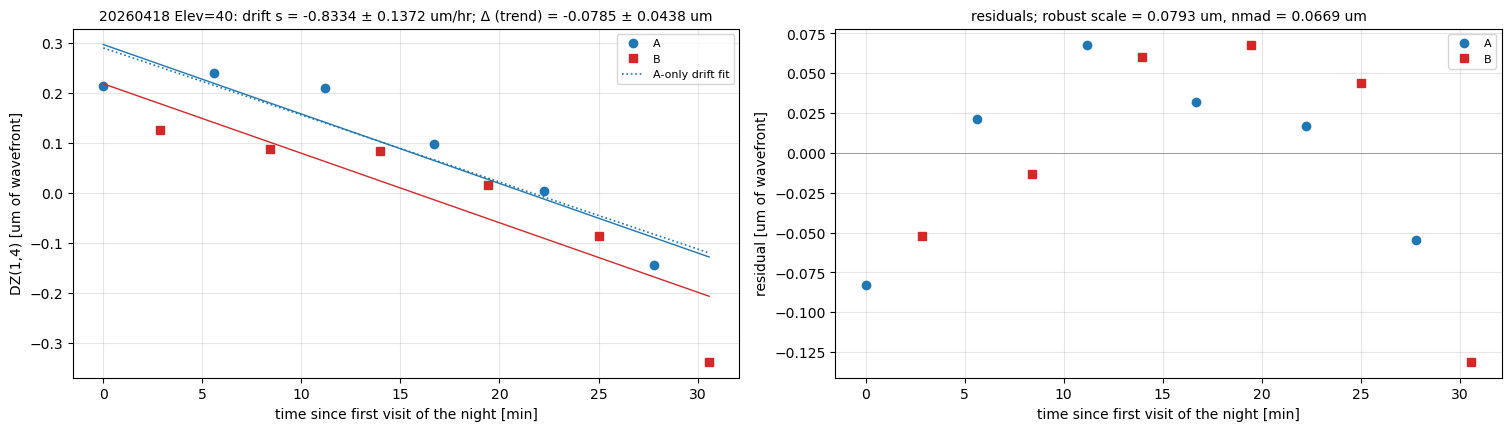

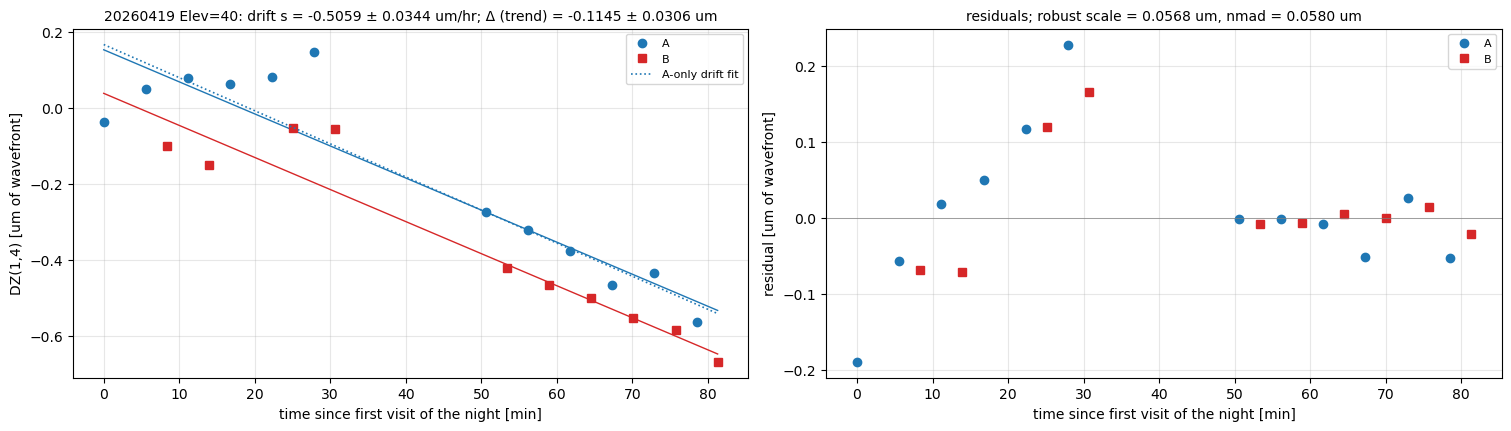

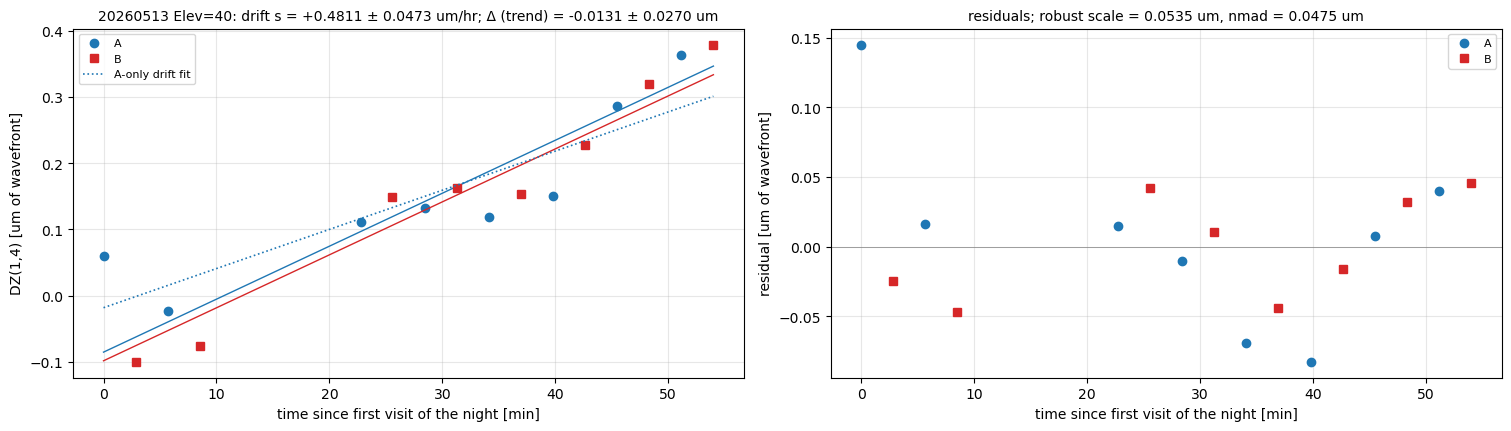

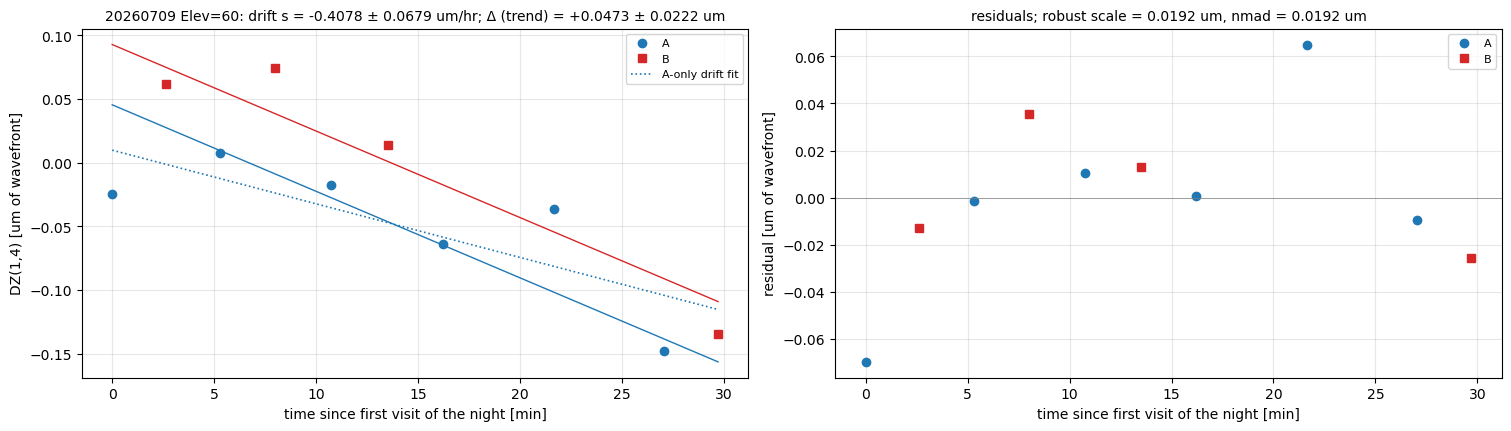

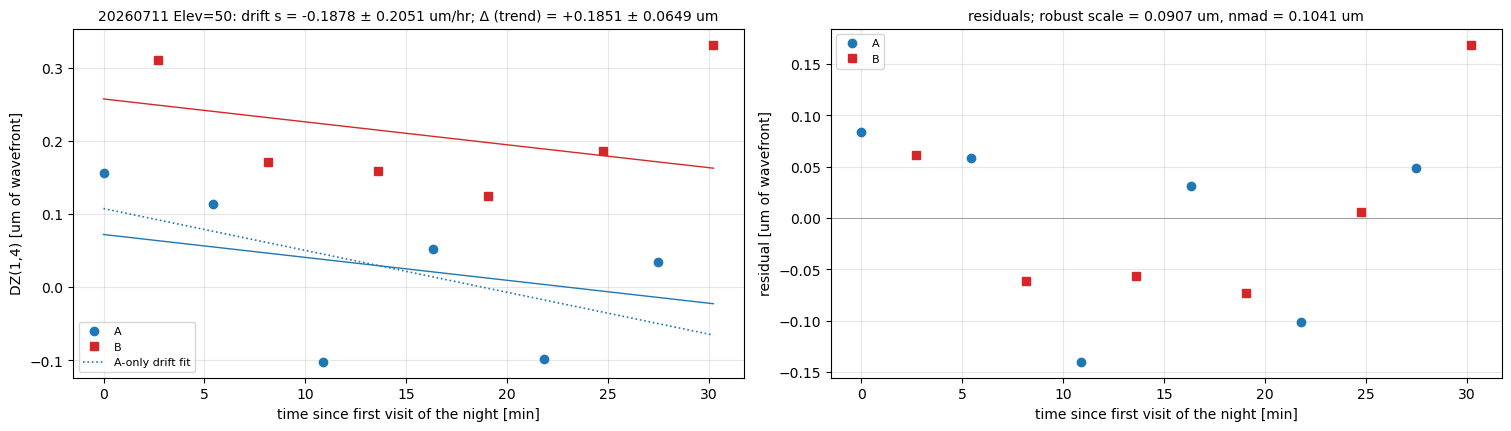

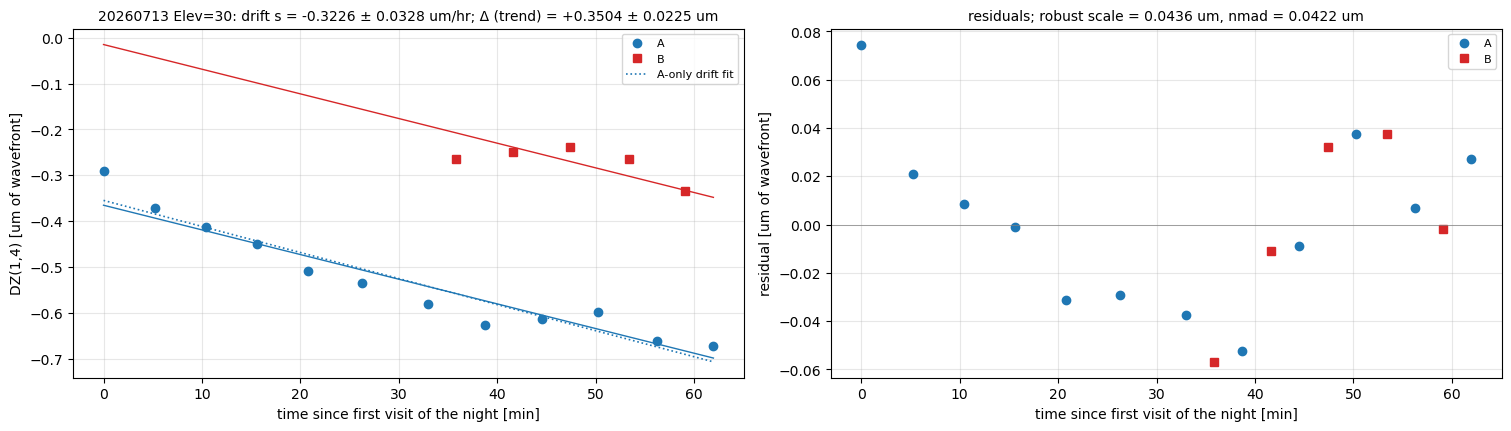

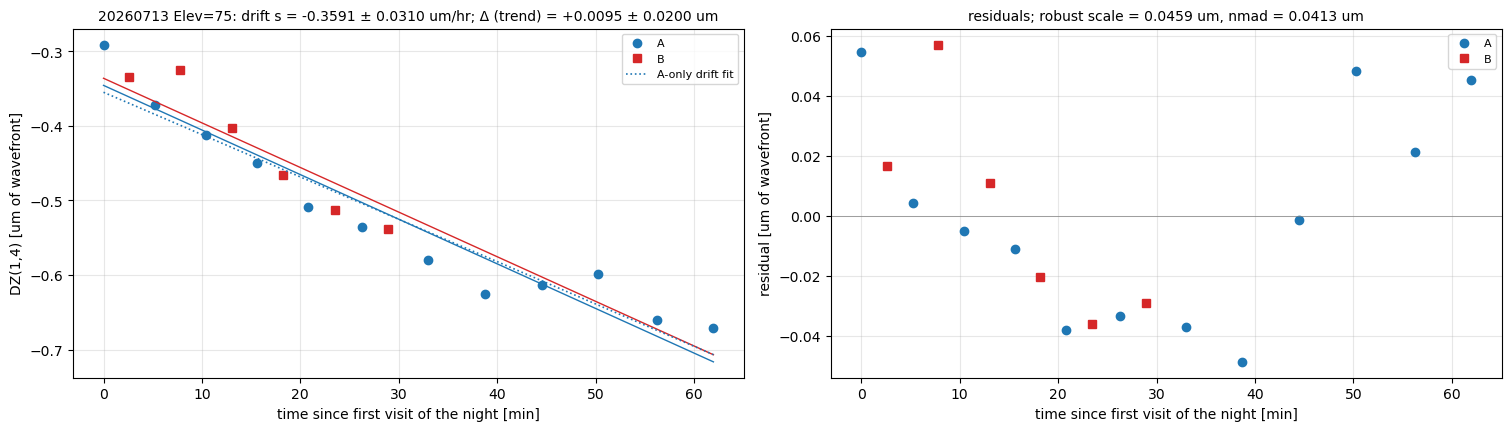

,night,leg,n_pairs,delta_um,err_um,n_aba,delta_aba_um,delta_aba_err_um,delta_trend_um,delta_trend_err_um,delta_step_um,slope_um_per_hr,slope_A_only_um_per_hr,mean_lag_min,lag_bias_um
0,20260418,Elev=40,6,-0.107188,0.017545,5,-0.068169,0.027485,-0.078508,0.043797,-0.106853,-0.833425,-0.804203,2.787864,-0.038725
1,20260419,Elev=40,10,-0.144455,0.008749,9,-0.121893,0.022311,-0.114536,0.030563,-0.183505,-0.505871,-0.522218,2.791333,-0.023534
2,20260513,Elev=40,8,0.032330,0.007045,7,0.008607,0.012700,-0.013081,0.026993,0.031150,0.481137,0.355667,2.830981,0.022702
3,20260709,Elev=60,4,0.048639,0.024631,3,0.070310,0.008900,0.047334,0.022205,0.069278,-0.407837,-0.252788,2.684768,-0.018249
4,20260711,Elev=50,6,0.207116,0.063007,5,0.175096,0.008267,0.185134,0.064860,0.187281,-0.187756,-0.343093,2.763077,-0.008646
5,20260713,Elev=30,5,0.333656,0.015238,5,0.366022,0.003457,0.350353,0.022540,0.269477,-0.322582,-0.340804,2.917070,-0.015683
6,20260713,Elev=75,6,-0.003203,0.009342,6,0.014634,0.007297,0.009545,0.019964,0.102247,-0.359125,-0.340804,2.624163,-0.015707


In [7]:
trend_rows = []
tfigs = []
for L in legs:
    d, lab = L['night'], L['leg']
    v = vdf[(vdf.night == d) & (vdf.leg == lab) & vdf.setting.isin(['A', 'B'])]
    t = v.t_min.to_numpy(); y = v.dz_um.to_numpy(); isb = (v.setting == 'B').to_numpy()
    f = huber_step_trend(t, y, isb)
    va = v[v.setting == 'A']
    ra = sm.RLM(va.dz_um.to_numpy(), sm.add_constant(va.t_min.to_numpy()),
                M=sm.robust.norms.HuberT(t=HUBER_T)).fit()
    lag = pdf_pairs[(pdf_pairs.night == d) & (pdf_pairs.leg == lab)]['lag_min'].mean()
    aba = paired_reduction(aba_diffs(v)) if len(aba_diffs(v)) else {'delta': np.nan, 'err': np.nan, 'n': 0}
    trend_rows.append({'night': d, 'leg': lab,
                       'delta_aba_um': aba['delta'], 'delta_aba_err_um': aba['err'],
                       'n_aba': aba['n'],
                       'slope_um_per_hr': f['s'] * 60, 'slope_err_um_per_hr': f['s_err'] * 60,
                       'slope_A_only_um_per_hr': ra.params[1] * 60,
                       'slope_A_only_err_um_per_hr': ra.bse[1] * 60,
                       'delta_trend_um': f['delta'], 'delta_trend_err_um': f['delta_err'],
                       'delta_step_um': f['delta0'], 'delta_step_err_um': f['delta0_err'],
                       'mean_lag_min': lag, 'lag_bias_um': f['s'] * lag})
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout='constrained')
    tg = np.linspace(t.min(), t.max(), 50)
    for s, mk, cl, off in (('A', 'o', '#1f77b4', 0.0), ('B', 's', '#d62728', f['delta'])):
        w = v[v.setting == s]
        ax[0].plot(w.t_min, w.dz_um, mk, color=cl, ms=6, label=s)
        ax[0].plot(tg, f['a'] + f['s'] * tg + off, '-', color=cl, lw=1)
    ax[0].plot(tg, ra.params[0] + ra.params[1] * tg, ':', color='#1f77b4', lw=1.2,
               label='A-only drift fit')
    ax[0].set_xlabel('time since first visit of the night [min]')
    ax[0].set_ylabel(f'DZ({K},{J}) [um of wavefront]')
    ax[0].set_title(f"{d} {lab}: drift s = {f['s']*60:+.4f} ± {f['s_err']*60:.4f} um/hr; "
                    f"Δ (trend) = {f['delta']:+.4f} ± {f['delta_err']:.4f} um", fontsize=10)
    ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
    res = y - (f['a'] + f['s'] * t + f['delta'] * isb)
    ax[1].plot(t[~isb], res[~isb], 'o', color='#1f77b4', label='A')
    ax[1].plot(t[isb], res[isb], 's', color='#d62728', label='B')
    ax[1].axhline(0, color='gray', lw=0.5)
    ax[1].set_xlabel('time since first visit of the night [min]')
    ax[1].set_ylabel('residual [um of wavefront]')
    ax[1].set_title(f"residuals; robust scale = {f['scale']:.4f} um, "
                    f"nmad = {nmad(res):.4f} um", fontsize=10)
    ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
    plt.show()
    tfigs.append(fig)
tdf = pd.DataFrame(trend_rows)
summ = summ.merge(tdf.drop(columns='mean_lag_min'), on=['night', 'leg'])
summ[['night', 'leg', 'n_pairs', 'delta_um', 'err_um', 'n_aba', 'delta_aba_um',
      'delta_aba_err_um', 'delta_trend_um',
      'delta_trend_err_um', 'delta_step_um', 'slope_um_per_hr',
      'slope_A_only_um_per_hr', 'mean_lag_min', 'lag_bias_um']]

<a id='errmodel'></a>
## Error model

Per-visit error on DZ_kj:

`sigma_i^2 = sigma_fit,i^2 + SIGMA_TURB_UM^2`

- **sigma_fit** is the shot-noise error of the DZ fit to the donuts: the Huber RLM
  coefficient error (`*_err` in `fits.parquet`, `lsst.ts.intrinsic.wavefront.dz_fitting`).
  It assumes independent donuts. Errors that are fixed in the field (the intrinsic
  map, CCD heights) are the same on A and B and cancel in Δ.
- **SIGMA_TURB_UM** is the stochastic wavefront from turbulence that is coherent
  across the field, so it does not average down with the number of donuts.

Three checks of the size of SIGMA_TURB_UM:

1. The fit errors themselves, and how they compare with `scale / sqrt(n_donuts)`.
2. CWFS against FAM at the corners (`wfs_corner_compare`): the covariance of the
   Z4 residual (CWFS minus the FAM interpolated to the corner) between pairs of
   corner sensors. The in-focus CWFS image is a different exposure from the FAM
   pair, so the residual holds two turbulence realisations; the covariance between
   sensors is the coherent part, `2 sigma_coh^2` if the two are independent.
3. The bounce data: the scatter of same-setting differences (A−A, B−B) per
   visit, `rms(Δy) / sqrt(2)`, against their time lag. White noise is flat in lag;
   a drift or a slow (red) process grows with lag.

In [8]:
import pyarrow.parquet as pq
fcols = ['day_obs', 'seq_num', 'n_donuts_1', f'{col}_err', f'{prefix}_z{J}_scale']
fx = pq.read_table(fits_path, columns=fcols).to_pandas()
vfit = vdf[vdf.setting.isin(['A', 'B'])].drop_duplicates(['night', 'seq_num']).merge(
    fx, left_on=['night', 'seq_num'], right_on=['day_obs', 'seq_num'])
naive = vfit[f'{prefix}_z{J}_scale'] / np.sqrt(vfit['n_donuts_1'])
print(f'{len(vfit)} A/B visits')
print(f'DZ({K},{J}) fit error sigma_fit: median {vfit[col + "_err"].median():.5f} um, '
      f'max {vfit[col + "_err"].max():.5f} um')
print(f'per-donut Huber scale: median {vfit[f"{prefix}_z{J}_scale"].median():.4f} um; '
      f'n_donuts median {vfit.n_donuts_1.median():.0f}; '
      f'scale/sqrt(n) median {naive.median():.5f} um')
print(f'SIGMA_TURB_UM = {SIGMA_TURB_UM} um; sigma_fit / SIGMA_TURB_UM median = '
      f'{vfit[col + "_err"].median() / SIGMA_TURB_UM:.3f} (dimensionless)')

95 A/B visits
DZ(1,4) fit error sigma_fit: median 0.00044 um, max 0.00095 um
per-donut Huber scale: median 0.0237 um; n_donuts median 3299; scale/sqrt(n) median 0.00041 um
SIGMA_TURB_UM = 0.04 um; sigma_fit / SIGMA_TURB_UM median = 0.011 (dimensionless)


### CWFS against FAM at the corners

Only meaningful for `J` measured by the CWFS. Each corner's Z_J residual has its
median removed; the covariance between two sensors is the robust form
`nmad((a+b)/2)^2 − nmad((a−b)/2)^2`. Plain covariances are printed too: they are
dominated by outliers.

In [9]:
from rubinwork.products import wfs_corner_compare
CWFS_VARIANT = 'd13-blitz_unpaired'
cc = wfs_corner_compare.load_table('wfs_corner_compare', CWFS_VARIANT)
cz = cc[cc.j == J].copy()
cz['res'] = cz.cwfs_median - cz.fam_interp
cz['res'] -= cz.groupby('corner').res.transform('median')
piv = cz.pivot_table(index=['day_obs', 'seq_num'], columns='corner', values='res')
crow = []
sens = list(piv.columns)
for i, a in enumerate(sens):
    for bb in sens[i + 1:]:
        m = piv[a].notna() & piv[bb].notna()
        xa, xb = piv[a][m], piv[bb][m]
        crow.append({'a': a, 'b': bb, 'n': int(m.sum()),
                     'cov_robust_um2': nmad((xa + xb) / 2) ** 2 - nmad((xa - xb) / 2) ** 2,
                     'cov_um2': np.cov(xa, xb)[0, 1]})
cdf = pd.DataFrame(crow)
cov_med = cdf.cov_robust_um2.median()
print(f'{CWFS_VARIANT}: {len(piv)} triplets, {len(sens)} sensors')
print('per-sensor nmad of residual [um]:',
      {s: round(nmad(piv[s].dropna()), 4) for s in sens})
print(f'median robust covariance between sensors = {cov_med:.4f} um^2 '
      f'-> sqrt = {np.sqrt(cov_med):.3f} um')
print(f'if CWFS and FAM carry independent coherent terms: sigma_coh = '
      f'sqrt(cov / 2) = {np.sqrt(cov_med / 2):.3f} um per exposure')
cdf.round(5)

d13-blitz_unpaired: 1836 triplets, 8 sensors
per-sensor nmad of residual [um]: {'R00_SW0': np.float64(0.1566), 'R00_SW1': np.float64(0.1511), 'R04_SW0': np.float64(0.1308), 'R04_SW1': np.float64(0.1281), 'R40_SW0': np.float64(0.1204), 'R40_SW1': np.float64(0.1185), 'R44_SW0': np.float64(0.1483), 'R44_SW1': np.float64(0.1333)}
median robust covariance between sensors = 0.0106 um^2 -> sqrt = 0.103 um
if CWFS and FAM carry independent coherent terms: sigma_coh = sqrt(cov / 2) = 0.073 um per exposure


,a,b,n,cov_robust_um2,cov_um2
0,R00_SW0,R00_SW1,1815,0.02002,-0.01685
1,R00_SW0,R04_SW0,1832,0.01220,0.04159
2,R00_SW0,R04_SW1,1804,0.01009,-0.02018
3,R00_SW0,R40_SW0,1833,0.01327,0.03597
4,R00_SW0,R40_SW1,1813,0.01036,-0.04663
5,R00_SW0,R44_SW0,1830,0.00226,0.05215
6,R00_SW0,R44_SW1,1809,0.00058,-0.04410
7,R00_SW1,R04_SW0,1816,0.01152,-0.00313
8,R00_SW1,R04_SW1,1792,0.01176,0.05550
9,R00_SW1,R40_SW0,1816,0.01076,0.00020


<a id='floor'></a>
## The white floor

The white (uncorrelated) part of the per-visit error is what remains as the time
lag between two visits goes to zero. v2 took it from the B−A pairs (lag about
2.8 min): the pair differences, with each sample's median removed, pooled over
samples, as `nmad / sqrt(2)`. That gave 0.022 um. It is biased low for three
reasons:

1. **nmad of a few values is low.** For a Gaussian, the expected nmad of n values
   is below sigma: 0.74 sigma at n = 4, 0.84 at n = 6, 0.91 at n = 10. Each sample
   has 4–10 pairs.
2. **Removing each sample's median removes one degree of freedom per sample**, a
   factor sqrt((n − 1) / n) on the rms (seven medians from 45 pairs).
3. **nmad ignores the tails.** The pair differences have outliers (0513 pair
   differences: nmad / sqrt(2) = 0.011 um, std / sqrt(2) = 0.053 um). A tail
   that shows up in the Δ errors must be in the error model. The rms is the
   honest variance; nmad is a robust estimate of the core only.

The table below gives each estimate, per sample and pooled. A second check uses
the A visits alone: each interior A minus the A interpolated from its two
neighbours (A–A–A, span about 11 min, so it also carries some red noise), per
visit `nmad / sqrt(1.5)`.

In [10]:
rng_b = np.random.default_rng(1)
nmad_bias = {n: np.mean([nmad(rng_b.normal(size=n)) for _ in range(20000)])
             for n in range(3, 13)}
fl = []
pp_ = pdf_pairs.copy()
grp = pp_.groupby(['night', 'leg']).diff_um
pp_['dc'] = pp_.diff_um - grp.transform('median')
pp_['nk'] = grp.transform('size')
for (n, lab), g in pp_.groupby(['night', 'leg']):
    d = g.diff_um.to_numpy()
    fl.append({'night': n, 'leg': lab, 'n_pairs': len(d),
               'nmad/sqrt2_um': nmad(d) / np.sqrt(2),
               'nmad/sqrt2/bias_um': nmad(d) / np.sqrt(2) / nmad_bias[len(d)],
               'std/sqrt2_um': np.std(d, ddof=1) / np.sqrt(2)})
fl = pd.DataFrame(fl)
dc_corr = pp_.dc * np.sqrt(pp_.nk / (pp_.nk - 1))
print(f'pooled over {len(pp_)} pairs, sample medians removed:')
print(f'  nmad / sqrt(2) = {nmad(pp_.dc) / np.sqrt(2):.4f} um   (v2 value)')
print(f'  nmad / sqrt(2), dof-corrected = {nmad(dc_corr) / np.sqrt(2):.4f} um')
print(f'  rms / sqrt(2), dof-corrected = {np.sqrt(np.mean(dc_corr ** 2) / 2):.4f} um')
aaa = []
for (n, lab), g in vdf[vdf.setting == 'A'].drop_duplicates(['night', 'leg', 'seq_num']).groupby(['night', 'leg']):
    g = g.sort_values('t_min'); t = g.t_min.to_numpy(); y = g.dz_um.to_numpy()
    for i in range(1, len(t) - 1):
        f = (t[i] - t[i - 1]) / (t[i + 1] - t[i - 1])
        aaa.append((n, t[i + 1] - t[i - 1], y[i] - (y[i - 1] + f * (y[i + 1] - y[i - 1]))))
aaa = pd.DataFrame(aaa, columns=['night', 'span_min', 'd_um'])
print(f'A–A–A ({len(aaa)} triples, median span {aaa.span_min.median():.1f} min): per visit '
      f'nmad / sqrt(1.5) = {nmad(aaa.d_um) / np.sqrt(1.5):.4f} um, '
      f'rms / sqrt(1.5) = {np.sqrt(np.mean(aaa.d_um ** 2) / 1.5):.4f} um')
fl.round(4)

pooled over 45 pairs, sample medians removed:
  nmad / sqrt(2) = 0.0215 um   (v2 value)
  nmad / sqrt(2), dof-corrected = 0.0231 um
  rms / sqrt(2), dof-corrected = 0.0436 um
A–A–A (48 triples, median span 11.2 min): per visit nmad / sqrt(1.5) = 0.0294 um, rms / sqrt(1.5) = 0.0456 um


,night,leg,n_pairs,nmad/sqrt2_um,nmad/sqrt2/bias_um,std/sqrt2_um
0,20260418,Elev=40,6,0.0242,0.0290,0.0315
1,20260419,Elev=40,10,0.0156,0.0171,0.0293
2,20260513,Elev=40,8,0.0112,0.0127,0.0528
3,20260709,Elev=60,4,0.0278,0.0376,0.0234
4,20260711,Elev=50,6,0.0871,0.1040,0.0761
5,20260713,Elev=30,5,0.0192,0.0233,0.0203
6,20260713,Elev=75,6,0.0129,0.0154,0.0211


<a id='variogram'></a>
## Variogram and red-noise model

The variogram is `D(tau) = < (y(t + tau) − y(t))^2 >` for two visits of one setting
on one night, tau apart. The B−A pairs, with their sample medians removed, add the
point at tau about 2.8 min. Model:

`D(tau) = 2 SIGMA_W^2 + SIGMA_R^2 (tau / T0)^ALPHA`, with T0 = 10 min.

- `SIGMA_W`: the white floor per visit, including the fit error.
- `SIGMA_R`: the rms change of the red part over 10 min; ALPHA = 2 is a pure
  linear drift, ALPHA = 1 a random walk, below 1 a process that saturates.

This is a power-law (fractional Brownian) structure function. Its covariance is
`C_ij = (SIGMA_W^2 + sigma_fit,i^2) δ_ij + SIGMA_R^2 / 2 [u_i^ALPHA + u_j^ALPHA − |u_i − u_j|^ALPHA]`,
u = t / T0. All four estimators are contrasts (their weights on the visits sum to
zero), so their variance depends only on D, not on the time origin. A drift of
either sign, one that changes during the night, or a jump all enter as red noise,
so the model needs no assumption about the drift.

The fit uses the mean square (not a robust version) in each lag bin, for the
reason in the previous section, with the error `D sqrt(2 / n)`. The robust
(median-based) fit and leave-one-night-out fits are printed for comparison.

mean-square fit: SIGMA_W = 0.0356 ± 0.0079 um, SIGMA_R = 0.1037 ± 0.0112 um (over 10 min), ALPHA = 1.62 ± 0.18 (dimensionless); chi2/dof = 0.1/3
robust fit:      SIGMA_W = 0.0000 um, SIGMA_R = 0.1137 um, ALPHA = 1.90; chi2/dof = 0.7/3
  without 20260418: SIGMA_W = 0.0417 um, SIGMA_R = 0.0849 um, ALPHA = 1.87
  without 20260419: SIGMA_W = 0.0100 um, SIGMA_R = 0.1227 um, ALPHA = 1.04
  without 20260513: SIGMA_W = 0.0292 um, SIGMA_R = 0.1102 um, ALPHA = 1.56
  without 20260709: SIGMA_W = 0.0360 um, SIGMA_R = 0.1072 um, ALPHA = 1.58
  without 20260711: SIGMA_W = 0.0220 um, SIGMA_R = 0.1081 um, ALPHA = 1.59
  without 20260713: SIGMA_W = 0.0421 um, SIGMA_R = 0.1043 um, ALPHA = 1.77


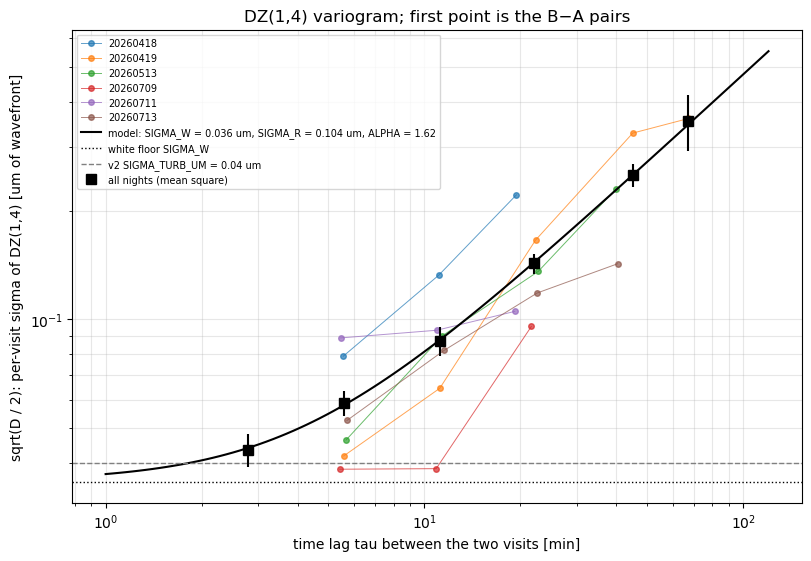

,n,lag_min,D_um2,D_err_um2,source
0,45,2.78784,0.00380,0.00080,B−A pairs
1,77,5.57583,0.00690,0.00111,same-setting
2,61,11.15526,0.01525,0.00276,same-setting
3,125,22.05626,0.04086,0.00517,same-setting
4,90,44.97006,0.12636,0.01884,same-setting
5,16,67.31121,0.25206,0.08912,same-setting


In [11]:
from scipy.optimize import least_squares
T0_MIN = 10.0
LAG_BINS = [0, 4, 8, 15, 30, 60, 120]   # min
vv = vdf[vdf.setting.isin(['A', 'B'])].drop_duplicates(['night', 'seq_num'])
sfr = []
for (n, s), g in vv.groupby(['night', 'setting']):
    g = g.sort_values('t_min'); tt = g.t_min.to_numpy(); yy = g.dz_um.to_numpy()
    for i in range(len(yy)):
        for j in range(i + 1, len(yy)):
            sfr.append((n, s, tt[j] - tt[i], yy[j] - yy[i]))
sf = pd.DataFrame(sfr, columns=['night', 'setting', 'lag_min', 'dy_um'])
sf['bin'] = pd.cut(sf.lag_min, LAG_BINS)

def vg_model(q, tau):
    return 2 * q[0] ** 2 + q[1] ** 2 * (tau / T0_MIN) ** q[2]

def variogram(sfx, ppx, robust=False):
    ms = (lambda x: np.median(np.asarray(x) ** 2) / 0.455) if robust else (lambda x: np.mean(np.asarray(x) ** 2))
    g = sfx.groupby('bin', observed=True).agg(n=('dy_um', 'size'), lag_min=('lag_min', 'median'),
                                              D_um2=('dy_um', ms)).reset_index(drop=True)
    c = ppx.dc * np.sqrt(ppx.nk / (ppx.nk - 1))
    ba = pd.DataFrame({'n': [len(ppx)], 'lag_min': [ppx.lag_min.median()], 'D_um2': [ms(c)]})
    out = pd.concat([ba, g], ignore_index=True)
    out['D_err_um2'] = out.D_um2 * np.sqrt(2 / out.n)
    out['source'] = ['B−A pairs'] + ['same-setting'] * len(g)
    return out

def fit_vg(t):
    r = least_squares(lambda q: (vg_model(q, t.lag_min.to_numpy()) - t.D_um2) / t.D_err_um2,
                      [0.03, 0.1, 1.5], bounds=([0, 0, 0.1], [1, 2, 2]))
    J_ = r.jac; cov = np.linalg.pinv(J_.T @ J_)
    return r.x, np.sqrt(np.diag(cov)), float((r.fun ** 2).sum()), len(t) - 3

vg = variogram(sf, pp_)
(SIGMA_W, SIGMA_R, ALPHA), qerr, c2, dof = fit_vg(vg)
print(f'mean-square fit: SIGMA_W = {SIGMA_W:.4f} ± {qerr[0]:.4f} um, SIGMA_R = {SIGMA_R:.4f} ± '
      f'{qerr[1]:.4f} um (over {T0_MIN:g} min), ALPHA = {ALPHA:.2f} ± {qerr[2]:.2f} '
      f'(dimensionless); chi2/dof = {c2:.1f}/{dof}')
qr, qre, c2r, dofr = fit_vg(variogram(sf, pp_, robust=True))
print(f'robust fit:      SIGMA_W = {qr[0]:.4f} um, SIGMA_R = {qr[1]:.4f} um, ALPHA = {qr[2]:.2f}; '
      f'chi2/dof = {c2r:.1f}/{dofr}')
for n in sorted(sf.night.unique()):
    q_, _, _, _ = fit_vg(variogram(sf[sf.night != n], pp_[pp_.night != n]))
    print(f'  without {n}: SIGMA_W = {q_[0]:.4f} um, SIGMA_R = {q_[1]:.4f} um, ALPHA = {q_[2]:.2f}')

ncol0 = {n: plt.get_cmap('tab10')(i % 10) for i, n in enumerate(sorted(vdf.night.unique()))}
fig_vg, ax = plt.subplots(figsize=(8, 5.5), layout='constrained')
for n, g in sf.groupby('night'):
    gg = g.groupby('bin', observed=True).agg(lag=('lag_min', 'median'),
                                            D=('dy_um', lambda x: np.mean(np.asarray(x) ** 2)),
                                            k=('dy_um', 'size'))
    gg = gg[gg.k >= 3]
    ax.plot(gg.lag, np.sqrt(gg.D / 2), 'o-', ms=4, lw=0.7, color=ncol0[n], alpha=0.7, label=str(n))
ax.errorbar(vg.lag_min, np.sqrt(vg.D_um2 / 2), yerr=vg.D_err_um2 / (2 * np.sqrt(2 * vg.D_um2)),
            fmt='ks', ms=7, label='all nights (mean square)')
tg = np.geomspace(1, 120, 100)
ax.plot(tg, np.sqrt(vg_model([SIGMA_W, SIGMA_R, ALPHA], tg) / 2), 'k-', lw=1.5,
        label=f'model: SIGMA_W = {SIGMA_W:.3f} um, SIGMA_R = {SIGMA_R:.3f} um, ALPHA = {ALPHA:.2f}')
ax.axhline(SIGMA_W, color='k', ls=':', lw=1, label='white floor SIGMA_W')
ax.axhline(SIGMA_TURB_UM, color='gray', ls='--', lw=1, label=f'v2 SIGMA_TURB_UM = {SIGMA_TURB_UM} um')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('time lag tau between the two visits [min]')
ax.set_ylabel(f'sqrt(D / 2): per-visit sigma of DZ({K},{J}) [um of wavefront]')
ax.set_title(f'DZ({K},{J}) variogram; first point is the B−A pairs')
ax.legend(fontsize=7); ax.grid(alpha=0.3, which='both')
plt.show()
vg.round(5)

<a id='esterr'></a>
## Estimator errors under the red-noise model

For each (night, leg), with the real visit times, settings and pairs, the DZ
values are replaced by Gaussian draws with the covariance C above, and each
estimator is rerun (Monte Carlo, N_MC realisations). Its sd over realisations is
its error under the model (`*_err_red_um`). The v2 white-noise errors
(SIGMA_TURB_UM) are computed the same way for comparison (`*_err_white_um`).

Then, within each night, a check of the model on the A–B–A differences: they are
a linear map M of the visits, so their covariance is `M C M^T` and their chi2
about their mean is `r^T (M C M^T)^-1 r` with n − 1 dof.

In [12]:
N_MC = 1000
rng = np.random.default_rng(20261029)

def run_estimators(v, pp, y):
    # the four Δ estimators on one (night, leg), for per-visit values y ordered like v
    ys = pd.Series(y, index=v.seq_num.to_numpy())
    d_pair = ys.loc[pp.seq_B.to_numpy()].to_numpy() - ys.loc[pp.seq_A.to_numpy()].to_numpy()
    f = huber_step_trend(v.t_min.to_numpy(), y, (v.setting == 'B').to_numpy())
    ab = aba_diffs(v.assign(dz_um=y))
    return (np.median(d_pair), f['delta0'], f['delta'], np.median(ab) if len(ab) else np.nan)

def red_cov(v):
    u = (v.t_min.to_numpy() - v.t_min.min()) / T0_MIN
    fit2 = np.nan_to_num(v.dz_err_um.to_numpy()) ** 2
    return (0.5 * SIGMA_R ** 2 * (u[:, None] ** ALPHA + u[None, :] ** ALPHA
                                  - np.abs(u[:, None] - u[None, :]) ** ALPHA)
            + np.diag(SIGMA_W ** 2 + fit2))

def aba_matrix(v):
    # rows: each A–B–A difference as weights on the visits of v
    s = v.setting.to_numpy(); t = v.t_min.to_numpy(); A = np.nonzero(s == 'A')[0]
    rows = []
    for i in np.nonzero(s == 'B')[0]:
        a0 = A[A < i]; a1 = A[A > i]
        if len(a0) and len(a1):
            a0, a1 = a0[-1], a1[0]; f = (t[i] - t[a0]) / (t[a1] - t[a0])
            w = np.zeros(len(s)); w[i] = 1; w[a0] -= 1 - f; w[a1] -= f
            rows.append(w)
    return np.array(rows)

mc_rows = []
for L in legs:
    d, lab = L['night'], L['leg']
    v = vdf[(vdf.night == d) & (vdf.leg == lab) & vdf.setting.isin(['A', 'B'])]
    v = v.drop_duplicates('seq_num').sort_values('seq_num')
    pp = pdf_pairs[(pdf_pairs.night == d) & (pdf_pairs.leg == lab)]
    C = red_cov(v)
    Lc = np.linalg.cholesky(C + 1e-12 * np.eye(len(v)))
    sig_w = np.sqrt(np.nan_to_num(v.dz_err_um.to_numpy()) ** 2 + SIGMA_TURB_UM ** 2)
    red = np.array([run_estimators(v, pp, Lc @ rng.normal(size=len(v))) for _ in range(N_MC)])
    wht = np.array([run_estimators(v, pp, rng.normal(0.0, sig_w)) for _ in range(N_MC)])
    sr, sw = np.nanstd(red, 0, ddof=1), np.nanstd(wht, 0, ddof=1)
    M = aba_matrix(v)
    r = M @ v.dz_um.to_numpy(); r = r - r.mean()
    CM = M @ C @ M.T
    mc_rows.append({'night': d, 'leg': lab,
                    'err_red_um': sr[0], 'delta_step_err_red_um': sr[1],
                    'delta_trend_err_red_um': sr[2], 'delta_aba_err_red_um': sr[3],
                    'err_white_um': sw[0], 'delta_step_err_white_um': sw[1],
                    'delta_trend_err_white_um': sw[2], 'delta_aba_err_white_um': sw[3],
                    'aba_corr_neighbour': (np.mean(np.diag(CM, 1) / np.sqrt(np.diag(CM)[:-1] * np.diag(CM)[1:]))
                                           if len(M) > 1 else np.nan),
                    'chi2_aba': float(r @ np.linalg.pinv(CM) @ r), 'dof_aba': len(M) - 1})
mdf = pd.DataFrame(mc_rows)
mdf['chi2/dof aba'] = mdf.chi2_aba / mdf.dof_aba
summ = summ.merge(mdf, on=['night', 'leg'])
summ[['night', 'leg', 'n_pairs', 'n_aba',
      'err_um', 'err_white_um', 'err_red_um',
      'delta_step_err_um', 'delta_step_err_red_um',
      'delta_trend_err_um', 'delta_trend_err_red_um',
      'delta_aba_err_um', 'delta_aba_err_white_um', 'delta_aba_err_red_um',
      'aba_corr_neighbour', 'chi2_aba', 'dof_aba', 'chi2/dof aba']].round(4)

,night,leg,n_pairs,n_aba,err_um,err_white_um,err_red_um,delta_step_err_um,delta_step_err_red_um,delta_trend_err_um,delta_trend_err_red_um,delta_aba_err_um,delta_aba_err_white_um,delta_aba_err_red_um,aba_corr_neighbour,chi2_aba,dof_aba,chi2/dof aba
0,20260418,Elev=40,6,5,0.0175,0.0260,0.0346,0.0900,0.0314,0.0438,0.0224,0.0275,0.0272,0.0257,0.1305,3.9256,4,0.9814
1,20260419,Elev=40,10,9,0.0087,0.0206,0.0288,0.1069,0.0629,0.0306,0.0201,0.0223,0.0217,0.0211,0.1068,6.6904,8,0.8363
2,20260513,Elev=40,8,7,0.0070,0.0229,0.0312,0.0983,0.0283,0.0270,0.0211,0.0127,0.0249,0.0243,0.1211,7.7320,6,1.2887
3,20260709,Elev=60,4,3,0.0246,0.0313,0.0368,0.0341,0.0290,0.0222,0.0287,0.0089,0.0351,0.0316,0.1300,0.1502,2,0.0751
4,20260711,Elev=50,6,5,0.0630,0.0267,0.0351,0.0560,0.0325,0.0649,0.0226,0.0083,0.0288,0.0269,0.1293,1.3477,4,0.3369
5,20260713,Elev=30,5,5,0.0152,0.0302,0.0395,0.0575,0.1382,0.0225,0.0310,0.0035,0.0276,0.0278,0.1277,0.6376,4,0.1594
6,20260713,Elev=75,6,6,0.0093,0.0265,0.0326,0.0560,0.1093,0.0200,0.0305,0.0073,0.0250,0.0226,0.1366,1.4970,5,0.2994


<a id='summary'></a>
## Summary

Δ vs B-set position from the four estimators. Nights at one position are spread
by 1 deg. Top row: the data-driven errors of v1. Bottom row: the red-noise model
errors. The chi2/dof of the 40 deg nights about their weighted mean is in each
title.

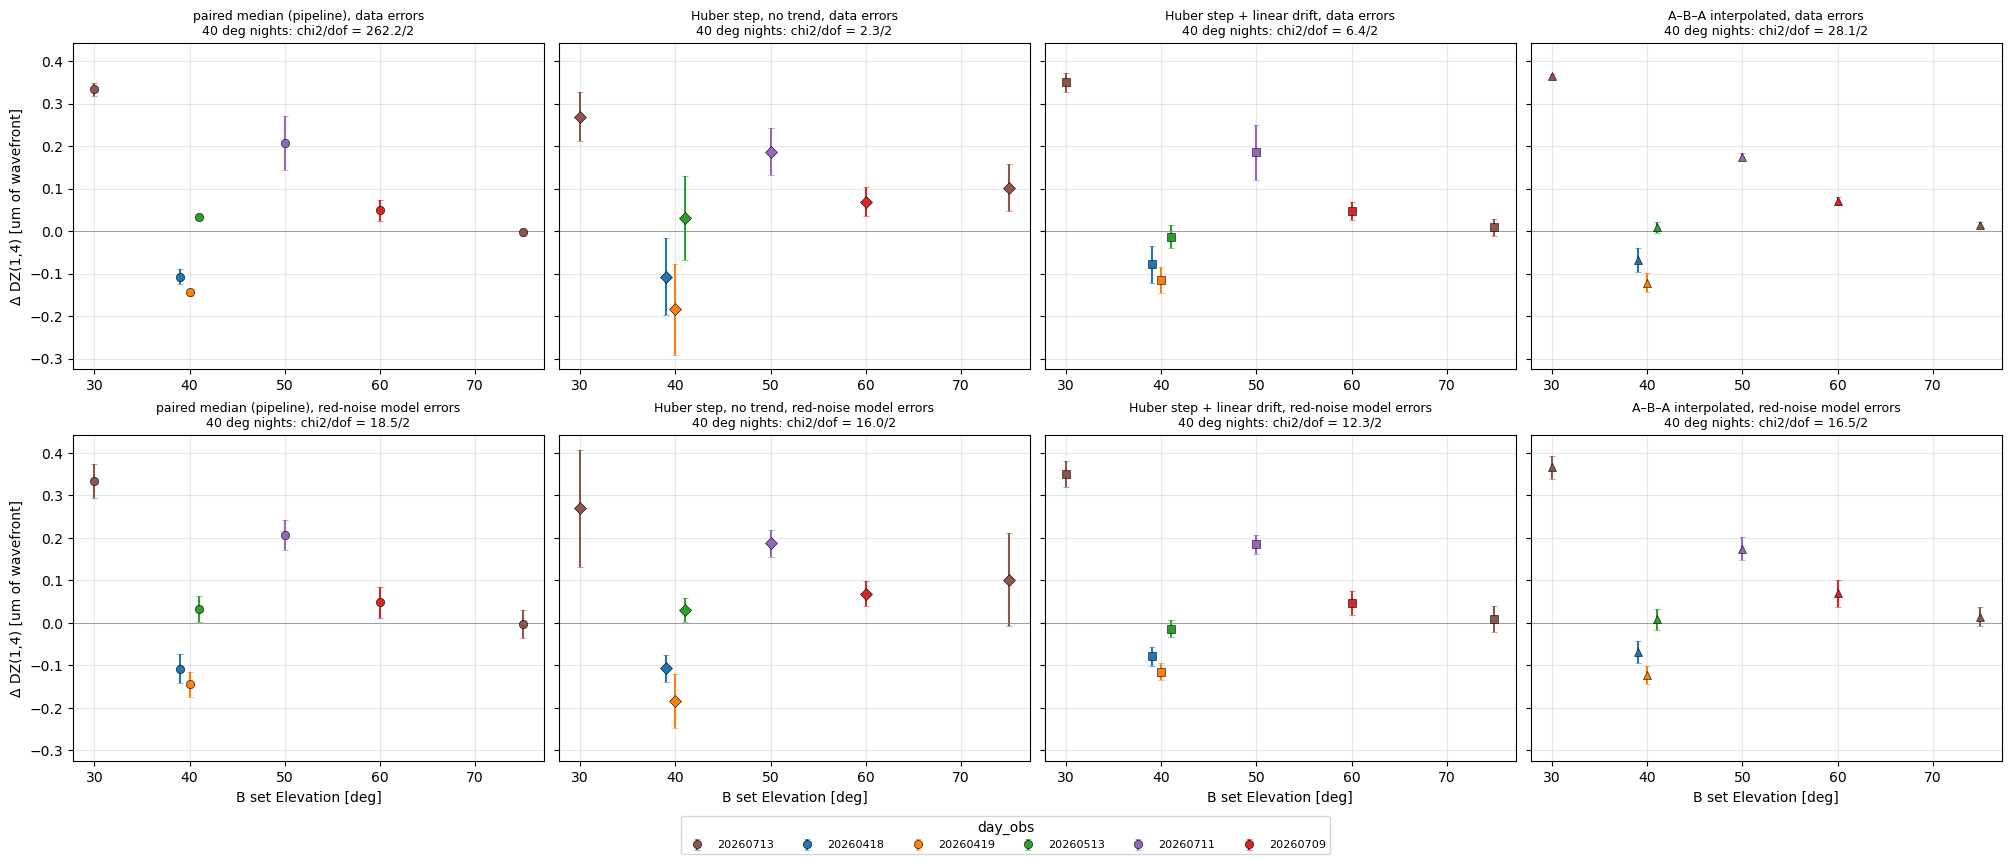

,estimator,errors,b_value_deg,weighted_mean_um,chi2,dof,chi2/dof
0,paired median (pipeline),data,40.0,-0.043,262.163,2,131.081
1,paired median (pipeline),red-noise model,40.0,-0.075,18.512,2,9.256
2,"Huber step, no trend",data,40.0,-0.083,2.302,2,1.151
3,"Huber step, no trend",red-noise model,40.0,-0.046,15.951,2,7.976
4,Huber step + linear drift,data,40.0,-0.061,6.380,2,3.190
5,Huber step + linear drift,red-noise model,40.0,-0.070,12.344,2,6.172
6,A–B–A interpolated,data,40.0,-0.030,28.131,2,14.066
7,A–B–A interpolated,red-noise model,40.0,-0.066,16.467,2,8.234


In [13]:
est = [('delta_um', 'err_um', 'err_red_um', 'paired median (pipeline)', 'o'),
       ('delta_step_um', 'delta_step_err_um', 'delta_step_err_red_um', 'Huber step, no trend', 'D'),
       ('delta_trend_um', 'delta_trend_err_um', 'delta_trend_err_red_um', 'Huber step + linear drift', 's'),
       ('delta_aba_um', 'delta_aba_err_um', 'delta_aba_err_red_um', 'A–B–A interpolated', '^')]
nights = sorted(summ.night.unique())
ncol = {n: plt.get_cmap('tab10')(i % 10) for i, n in enumerate(nights)}
fig, ax = plt.subplots(2, 4, figsize=(20, 8.5), layout='constrained', sharey=True)
c2rows = []
for ai, (dc, ec, emc, name, mk) in enumerate(est):
    for ri, (eset, ecol) in enumerate((('data', ec), ('red-noise model', emc))):
        a_ = ax[ri, ai]
        for bv, g in summ.groupby('b_value_deg'):
            g = g.sort_values('night')
            off = (np.arange(len(g)) - (len(g) - 1) / 2) * 1.0
            for (_, r), dx in zip(g.iterrows(), off):
                a_.errorbar(bv + dx, r[dc], yerr=r[ecol], fmt=mk, color=ncol[r.night],
                            mec='k', mew=0.4, capsize=2, label=str(r.night))
            if len(g) > 1:
                w = 1 / g[ecol] ** 2
                m = np.sum(w * g[dc]) / np.sum(w)
                c2 = np.sum(w * (g[dc] - m) ** 2)
                c2rows.append({'estimator': name, 'errors': eset, 'b_value_deg': bv,
                               'weighted_mean_um': m, 'chi2': c2, 'dof': len(g) - 1})
                a_.set_title(f'{name}, {eset} errors\n{bv:g} deg nights: chi2/dof = '
                             f'{c2:.1f}/{len(g) - 1}', fontsize=9)
        a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3)
        if ri == 1:
            a_.set_xlabel(f'B set {bl.leg_axis_name(b)} [deg]')
ax[0, 0].set_ylabel(f'Δ DZ({K},{J}) [um of wavefront]')
ax[1, 0].set_ylabel(f'Δ DZ({K},{J}) [um of wavefront]')
h, l = ax[0, 0].get_legend_handles_labels()
u = dict(zip(l, h))
fig.legend(u.values(), u.keys(), loc='outside lower center', ncols=len(u), fontsize=8, title='day_obs')
plt.show()
c2df = pd.DataFrame(c2rows)
c2df['chi2/dof'] = c2df.chi2 / c2df.dof
c2df.round(3)

### Extra scatter still needed between nights

The error added in quadrature to every 40 deg night, on top of the red-noise
errors, that brings the chi2/dof of the nights to 1. Zero means the red-noise
model accounts for the night-to-night scatter.

In [14]:
from scipy.optimize import brentq
xrows = []
for dc, ec, emc, name, mk in est:
    for bv, g in summ.groupby('b_value_deg'):
        if len(g) < 2:
            continue
        x, e = g[dc].to_numpy(), g[emc].to_numpy()
        def c2n(s):
            w = 1 / (e ** 2 + s ** 2); m = np.sum(w * x) / np.sum(w)
            return np.sum(w * (x - m) ** 2) / (len(x) - 1) - 1
        s_x = 0.0 if c2n(0.0) <= 0 else brentq(c2n, 0.0, 5.0)
        w = 1 / (e ** 2 + s_x ** 2)
        xrows.append({'estimator': name, 'b_value_deg': bv, 'sigma_extra_um': s_x,
                      'weighted_mean_um': np.sum(w * x) / np.sum(w),
                      'weighted_mean_err_um': 1 / np.sqrt(np.sum(w))})
xdf = pd.DataFrame(xrows)
xdf.round(4)

,estimator,b_value_deg,sigma_extra_um,weighted_mean_um,weighted_mean_err_um
0,paired median (pipeline),40.0,0.0880,-0.0732,0.0540
1,"Huber step, no trend",40.0,0.0993,-0.0782,0.0622
2,Huber step + linear drift,40.0,0.0471,-0.0689,0.0298
3,A–B–A interpolated,40.0,0.0614,-0.0611,0.0380


<a id='signif'></a>
## How far are the 40 deg points from the rest?

For each estimator, with the red-noise errors:

- **40 deg mean**: the weighted mean of the three nights. Its error is scaled by
  sqrt(chi2/dof) when chi2/dof > 1 (PDG scale factor), so the night-to-night
  scatter is in it.
- **pull of each other point** from the 40 deg mean: `(Δ_i − m40) / sqrt(e_i^2 + e_m40^2)`.
- **pull of the 40 deg mean from the other points' trend**: a weighted LS fit of
  `Δ = c1 (x − 70) + c2 (x − 70)^2` (the LUT form, zero at the 70 deg reference) to
  the 30, 50, 60 and 75 deg points (4 points, 2 parameters), evaluated at 40 deg
  with its error, against the 40 deg mean.

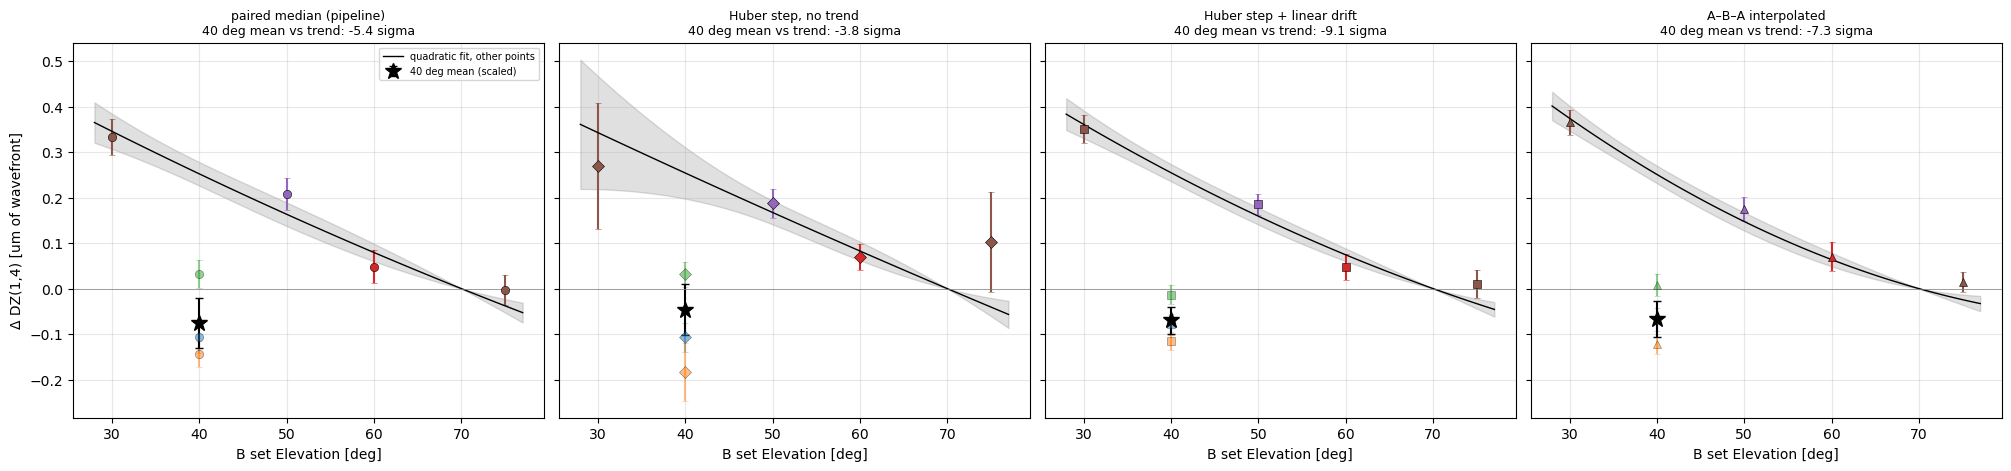

,0,1,2,3
estimator,paired median (pipeline),"Huber step, no trend",Huber step + linear drift,A–B–A interpolated
m40_um,-0.075,-0.046,-0.07,-0.066
m40_err_um,0.018,0.02,0.012,0.014
chi2_40,18.512,15.951,12.344,16.467
dof_40,2,2,2,2
scale_factor,3.042,2.824,2.484,2.869
m40_err_scaled_um,0.055,0.056,0.03,0.039
trend_at_40_um,0.252,0.254,0.255,0.251
trend_at_40_err_um,0.026,0.057,0.019,0.019
chi2_trend_fit,3.471,2.576,4.273,4.174


In [15]:
sig_rows = []
fig_sig, axs = plt.subplots(1, 4, figsize=(20, 4.6), layout='constrained', sharey=True)
for ai, (dc, ec, emc, name, mk) in enumerate(est):
    g40 = summ[summ.b_value_deg == 40.0]
    x, e = g40[dc].to_numpy(), g40[emc].to_numpy()
    w = 1 / e ** 2; m40 = np.sum(w * x) / np.sum(w); em = 1 / np.sqrt(np.sum(w))
    c2 = np.sum(w * (x - m40) ** 2); S = max(1.0, np.sqrt(c2 / (len(x) - 1)))
    em_s = em * S
    oth = summ[summ.b_value_deg != 40.0]
    xo, yo, eo = oth.b_value_deg.to_numpy() - 70.0, oth[dc].to_numpy(), oth[emc].to_numpy()
    X = np.column_stack([xo, xo ** 2]) / eo[:, None]
    cov = np.linalg.inv(X.T @ X); c = cov @ X.T @ (yo / eo)
    chi2_o = float(np.sum((X @ c - yo / eo) ** 2))
    g = np.array([-30.0, 900.0]); pred = g @ c; epred = np.sqrt(g @ cov @ g)
    row = {'estimator': name, 'm40_um': m40, 'm40_err_um': em, 'chi2_40': c2, 'dof_40': len(x) - 1,
           'scale_factor': S, 'm40_err_scaled_um': em_s,
           'trend_at_40_um': pred, 'trend_at_40_err_um': epred,
           'chi2_trend_fit': chi2_o, 'dof_trend_fit': len(xo) - 2,
           'pull_40_vs_trend': (m40 - pred) / np.hypot(em_s, epred)}
    for _, r in oth.iterrows():
        row[f'pull_{r.leg}'] = (r[dc] - m40) / np.hypot(r[emc], em_s)
    sig_rows.append(row)
    a_ = axs[ai]
    for _, r in summ.iterrows():
        a_.errorbar(r.b_value_deg, r[dc], yerr=r[emc], fmt=mk, color=ncol[r.night], mec='k', mew=0.4,
                    capsize=2, alpha=0.5 if r.b_value_deg == 40 else 1)
    a_.errorbar(40, m40, yerr=em_s, fmt='*', color='k', ms=12, capsize=3, label='40 deg mean (scaled)')
    xg = np.linspace(-42, 7, 100)
    yg = c[0] * xg + c[1] * xg ** 2
    eg = np.sqrt(np.einsum('ij,jk,ik->i', np.column_stack([xg, xg ** 2]), cov, np.column_stack([xg, xg ** 2])))
    a_.plot(xg + 70, yg, 'k-', lw=1, label='quadratic fit, other points')
    a_.fill_between(xg + 70, yg - eg, yg + eg, color='k', alpha=0.12)
    a_.axhline(0, color='gray', lw=0.5); a_.grid(alpha=0.3)
    a_.set_title(f'{name}\n40 deg mean vs trend: {row["pull_40_vs_trend"]:+.1f} sigma', fontsize=9)
    a_.set_xlabel(f'B set {bl.leg_axis_name(b)} [deg]')
axs[0].set_ylabel(f'Δ DZ({K},{J}) [um of wavefront]'); axs[0].legend(fontsize=7)
plt.show()
sig_df = pd.DataFrame(sig_rows)
figs_all = figs + tfigs + [fig_vg, fig, fig_sig]
sig_df.round(3).T

In [16]:
if SAVE:
    out = run.path / f'bounce_delta_derivation_dz{K}_{J}.pdf'
    with PdfPages(str(out)) as pdf:
        for f in [fig, fig_sig, fig_vg] + figs + tfigs:
            pdf.savefig(f, bbox_inches='tight')
    summ.to_csv(run.path / f'bounce_delta_derivation_dz{K}_{J}.csv', index=False)
    xdf.to_csv(run.path / f'bounce_delta_extra_sigma_dz{K}_{J}.csv', index=False)
    c2df.to_csv(run.path / f'bounce_delta_chi2_dz{K}_{J}.csv', index=False)
    vg.to_csv(run.path / f'bounce_delta_variogram_dz{K}_{J}.csv', index=False)
    sig_df.to_csv(run.path / f'bounce_delta_significance_dz{K}_{J}.csv', index=False)
    vdf.to_csv(run.path / f'bounce_delta_visits_dz{K}_{J}.csv', index=False)
    pdf_pairs.to_csv(run.path / f'bounce_delta_pairs_dz{K}_{J}.csv', index=False)
    print(f'wrote {out}')

wrote /sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/bounce/20261029_delta_derivation_v3_dz1_4/bounce_delta_derivation_dz1_4.pdf
